## About Dataset
Context
This is a small subset of dataset of Book reviews from Amazon Kindle Store category.

Content
5-core dataset of product reviews from Amazon Kindle Store category from May 1996 - July 2014. Contains total of 982619 entries. Each reviewer has at least 5 reviews and each product has at least 5 reviews in this dataset.
Columns

- asin - ID of the product, like B000FA64PK
- helpful - helpfulness rating of the review - example: 2/3.
- overall - rating of the product.
- reviewText - text of the review (heading).
- reviewTime - time of the review (raw).
- reviewerID - ID of the reviewer, like A3SPTOKDG7WBLN
- reviewerName - name of the reviewer.
- summary - summary of the review (description).
- unixReviewTime - unix timestamp.

Acknowledgements
This dataset is taken from Amazon product data, Julian McAuley, UCSD website. http://jmcauley.ucsd.edu/data/amazon/

License to the data files belong to them.

Inspiration
- Sentiment analysis on reviews.
- Understanding how people rate usefulness of a review/ What factors influence helpfulness of a review.
- Fake reviews/ outliers.
- Best rated product IDs, or similarity between products based on reviews alone (not the best idea ikr).
- Any other interesting analysis

#### Best Practises
1. Preprocessing And Cleaning
2. Train Test Split
3. BOW,TFIDF,Word2vec
4. Train ML algorithms

In [94]:
# Load the dataset
import pandas as pd
data=pd.read_csv('all_kindle_review.csv')
data.head()

,Unnamed: 0.1,Unnamed: 0,asin,helpful,rating,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime
0,0,11539,B0033UV8HI,"[8, 10]",3,"Jace Rankin may be short, but he's nothing to ...","09 2, 2010",A3HHXRELK8BHQG,Ridley,Entertaining But Average,1283385600
1,1,5957,B002HJV4DE,"[1, 1]",5,Great short read. I didn't want to put it dow...,"10 8, 2013",A2RGNZ0TRF578I,Holly Butler,Terrific menage scenes!,1381190400
2,2,9146,B002ZG96I4,"[0, 0]",3,I'll start by saying this is the first of four...,"04 11, 2014",A3S0H2HV6U1I7F,Merissa,Snapdragon Alley,1397174400
3,3,7038,B002QHWOEU,"[1, 3]",3,Aggie is Angela Lansbury who carries pocketboo...,"07 5, 2014",AC4OQW3GZ919J,Cleargrace,very light murder cozy,1404518400
4,4,1776,B001A06VJ8,"[0, 1]",4,I did not expect this type of book to be in li...,"12 31, 2012",A3C9V987IQHOQD,Rjostler,Book,1356912000


In [95]:
df=data[['reviewText','rating']]
df.head()

,reviewText,rating
0,"Jace Rankin may be short, but he's nothing to ...",3
1,Great short read. I didn't want to put it dow...,5
2,I'll start by saying this is the first of four...,3
3,Aggie is Angela Lansbury who carries pocketboo...,3
4,I did not expect this type of book to be in li...,4


In [96]:
df.shape

(12000, 2)

In [97]:
## Missing Values
df.isnull().sum()

,0
reviewText,0
rating,0


In [98]:
df['rating'].unique()

array([3, 5, 4, 2, 1])

In [99]:
df['rating'].value_counts()

,count
rating,
5,3000
4,3000
3,2000
2,2000
1,2000


## Preprocessing And Cleaning

In [100]:
## postive review is 1 and negative review is 0
df['rating']=df['rating'].apply(lambda x:0 if x<3 else 1)

/tmp/ipykernel_713/3208188810.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['rating']=df['rating'].apply(lambda x:0 if x<3 else 1)


In [101]:
df['rating'].value_counts()

,count
rating,
1,8000
0,4000


In [102]:
## 1. Lower All the cases
df['reviewText']=df['reviewText'].str.lower()

/tmp/ipykernel_713/1654308119.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['reviewText']=df['reviewText'].str.lower()


In [103]:
df.head()

,reviewText,rating
0,"jace rankin may be short, but he's nothing to ...",1
1,great short read. i didn't want to put it dow...,1
2,i'll start by saying this is the first of four...,1
3,aggie is angela lansbury who carries pocketboo...,1
4,i did not expect this type of book to be in li...,1


In [104]:
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [105]:
df['rating'].value_counts()

,count
rating,
1,8000
0,4000


In [106]:
%pip install beautifulsoup4

In [107]:
from bs4 import BeautifulSoup

In [108]:
## Removing special characters
df['reviewText']=df['reviewText'].apply(lambda x:re.sub('[^a-z A-z 0-9-]+', '',x))
## Remove the stopswords
df['reviewText']=df['reviewText'].apply(lambda x:" ".join([y for y in x.split() if y not in stopwords.words('english')]))
## Remove url
df['reviewText']=df['reviewText'].apply(lambda x: re.sub(r'(http|https|ftp|ssh)://([\w_-]+(?:(?:\.[\w_-]+)+))([\w.,@?^=%&:/~+#-]*[\w@?^=%&/~+#-])?', '' , str(x)))
## Remove html tags
df['reviewText']=df['reviewText'].apply(lambda x: BeautifulSoup(x, 'lxml').get_text())
## Remove any additional spaces
df['reviewText']=df['reviewText'].apply(lambda x: " ".join(x.split()))


/tmp/ipykernel_713/1658462958.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['reviewText']=df['reviewText'].apply(lambda x:re.sub('[^a-z A-z 0-9-]+', '',x))
/tmp/ipykernel_713/1658462958.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['reviewText']=df['reviewText'].apply(lambda x:" ".join([y for y in x.split() if y not in stopwords.words('english')]))
/tmp/ipykernel_713/1658462958.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[

In [109]:
df.head()

,reviewText,rating
0,jace rankin may short hes nothing mess man hau...,1
1,great short read didnt want put read one sitti...,1
2,ill start saying first four books wasnt expect...,1
3,aggie angela lansbury carries pocketbooks inst...,1
4,expect type book library pleased find price right,1


In [110]:
## Lemmatizer
from nltk.stem import WordNetLemmatizer

In [111]:
lemmatizer=WordNetLemmatizer()

In [112]:
def lemmatize_words(text):
    return " ".join([lemmatizer.lemmatize(word) for word in text.split()])


In [113]:
import nltk
nltk.download('wordnet')
df['reviewText']=df['reviewText'].apply(lambda x:lemmatize_words(x))

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
/tmp/ipykernel_713/137616133.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['reviewText']=df['reviewText'].apply(lambda x:lemmatize_words(x))


In [114]:
df.head()

,reviewText,rating
0,jace rankin may short he nothing mess man haul...,1
1,great short read didnt want put read one sitti...,1
2,ill start saying first four book wasnt expecti...,1
3,aggie angela lansbury carry pocketbook instead...,1
4,expect type book library pleased find price right,1


In [115]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(df['reviewText'],df['rating'],
                                              test_size=0.20)

In [116]:
from sklearn.feature_extraction.text import CountVectorizer
bow=CountVectorizer()
X_train_bow=bow.fit_transform(X_train).toarray()
X_test_bow=bow.transform(X_test).toarray()

In [117]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer()
X_train_tfidf=tfidf.fit_transform(X_train).toarray()
X_test_tfidf=tfidf.transform(X_test).toarray()

In [118]:
%pip install gensim

In [119]:
import numpy as np
from gensim.models import Word2Vec

# Word2Vec needs a list of tokens per review, not a raw string
train_tokens = [text.split() for text in X_train]
test_tokens  = [text.split() for text in X_test]

# Train only on the training set (avoids leaking test data)
w2v = Word2Vec(
    sentences=train_tokens,
    vector_size=100,   # embedding dimension
    window=5,          # context window
    min_count=2,       # ignore very rare words
    workers=4,
    sg=0,              # 0 = CBOW, 1 = Skip-gram
    epochs=10
)

print(w2v.wv.most_similar('boring', topn=5))   # quick sanity check

[('confusing', 0.903377115726471), ('predictable', 0.8671531677246094), ('rushed', 0.8527590036392212), ('repetitive', 0.8504940271377563), ('lacking', 0.8488715887069702)]


In [120]:
from sklearn.naive_bayes import GaussianNB

In [121]:
def avg_word2vec(tokens, model):
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    if len(vecs) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vecs, axis=0)

X_train_w2v = np.array([avg_word2vec(t, w2v) for t in train_tokens])
X_test_w2v  = np.array([avg_word2vec(t, w2v) for t in test_tokens])

In [122]:
nb_model_w2v = GaussianNB().fit(X_train_w2v, y_train)
y_pred_w2v = nb_model_w2v.predict(X_test_w2v)

print("Word2Vec accuracy:", accuracy_score(y_test, y_pred_w2v))
print(confusion_matrix(y_test, y_pred_w2v))
print(classification_report(y_test, y_pred_w2v))

Word2Vec accuracy: 0.7358333333333333
[[ 637  181]
 [ 453 1129]]
              precision    recall  f1-score   support

           0       0.58      0.78      0.67       818
           1       0.86      0.71      0.78      1582

    accuracy                           0.74      2400
   macro avg       0.72      0.75      0.72      2400
weighted avg       0.77      0.74      0.74      2400



In [123]:
X_train_bow

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [124]:
nb_model_bow=GaussianNB().fit(X_train_bow,y_train)
nb_model_tfidf=GaussianNB().fit(X_train_tfidf,y_train)

In [125]:
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

In [126]:
y_pred_bow=nb_model_bow.predict(X_test_bow)

In [127]:
y_pred_tfidf=nb_model_tfidf.predict(X_test_tfidf)

In [128]:
confusion_matrix(y_test,y_pred_bow)

array([[546, 272],
       [732, 850]])

In [129]:
print("BOW accuracy: ",accuracy_score(y_test,y_pred_bow))

BOW accuracy:  0.5816666666666667


In [130]:
confusion_matrix(y_test,y_pred_tfidf)

array([[532, 286],
       [704, 878]])

In [131]:
print("TFIDF accuracy: ",accuracy_score(y_test,y_pred_tfidf))

TFIDF accuracy:  0.5875


In [92]:
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Feature sets: name -> (X_train, X_test)
features = {
    "BOW":      (X_train_bow,   X_test_bow),
    "TF-IDF":   (X_train_tfidf, X_test_tfidf),
    "Word2Vec": (X_train_w2v,   X_test_w2v),
}

# Classifiers (fresh instance is created for each feature set below)
classifiers = {
    "GaussianNB":         lambda: GaussianNB(),
    "LogisticRegression": lambda: LogisticRegression(max_iter=1000),
    "RandomForest":       lambda: RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

results = []
details = {}

for feat_name, (Xtr, Xte) in features.items():
    for clf_name, make_clf in classifiers.items():
        model = make_clf().fit(Xtr, y_train)
        y_pred = model.predict(Xte)

        results.append({
            "Features":   feat_name,
            "Model":      clf_name,
            "Accuracy":   accuracy_score(y_test, y_pred),
            "Precision":  precision_score(y_test, y_pred),
            "Recall":     recall_score(y_test, y_pred),
            "F1":         f1_score(y_test, y_pred),
        })
        details[(feat_name, clf_name)] = (
            confusion_matrix(y_test, y_pred),
            classification_report(y_test, y_pred)
        )

results_df = (pd.DataFrame(results)
                .sort_values("Accuracy", ascending=False)
                .reset_index(drop=True))

print("===== SUMMARY (sorted by accuracy) =====")
display(results_df.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}",
    "Recall": "{:.4f}", "F1": "{:.4f}"
}).background_gradient(subset=["Accuracy", "F1"], cmap="Greens"))

print("\n===== DETAILED RESULTS =====")
for (feat_name, clf_name), (cm, report) in details.items():
    print(f"\n--- {feat_name} + {clf_name} ---")
    print("Confusion matrix:\n", cm)
    print(report)

===== SUMMARY (sorted by accuracy) =====


,Features,Model,Accuracy,Precision,Recall,F1
0,TF-IDF,LogisticRegression,0.8329,0.8333,0.9330,0.8803
1,BOW,LogisticRegression,0.8308,0.8598,0.8880,0.8737
2,TF-IDF,RandomForest,0.7892,0.7689,0.9722,0.8587
3,Word2Vec,LogisticRegression,0.7858,0.8104,0.8811,0.8442
4,BOW,RandomForest,0.7842,0.7699,0.9589,0.8541
5,Word2Vec,RandomForest,0.7667,0.7953,0.8697,0.8308
6,Word2Vec,GaussianNB,0.7254,0.8519,0.7059,0.7721
7,BOW,GaussianNB,0.5737,0.7422,0.5408,0.6257
8,TF-IDF,GaussianNB,0.5737,0.7360,0.5503,0.6298



===== DETAILED RESULTS =====

--- BOW + GaussianNB ---
Confusion matrix:
 [[522 297]
 [726 855]]
              precision    recall  f1-score   support

           0       0.42      0.64      0.51       819
           1       0.74      0.54      0.63      1581

    accuracy                           0.57      2400
   macro avg       0.58      0.59      0.57      2400
weighted avg       0.63      0.57      0.58      2400


--- BOW + LogisticRegression ---
Confusion matrix:
 [[ 590  229]
 [ 177 1404]]
              precision    recall  f1-score   support

           0       0.77      0.72      0.74       819
           1       0.86      0.89      0.87      1581

    accuracy                           0.83      2400
   macro avg       0.81      0.80      0.81      2400
weighted avg       0.83      0.83      0.83      2400


--- BOW + RandomForest ---
Confusion matrix:
 [[ 366  453]
 [  65 1516]]
              precision    recall  f1-score   support

           0       0.85      0.45      

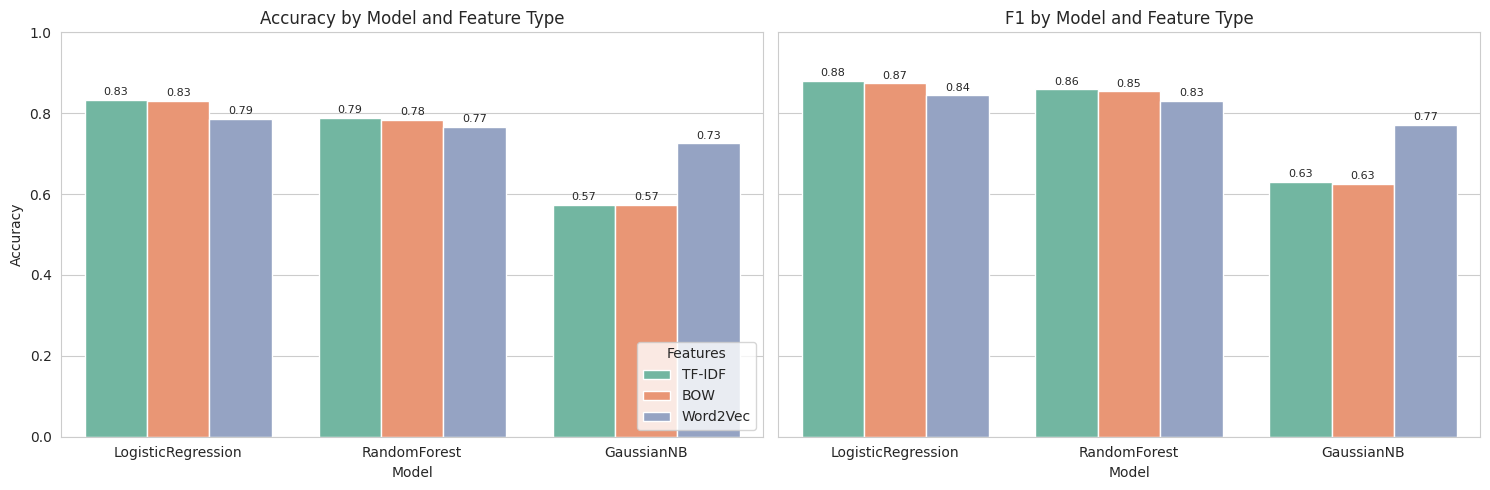

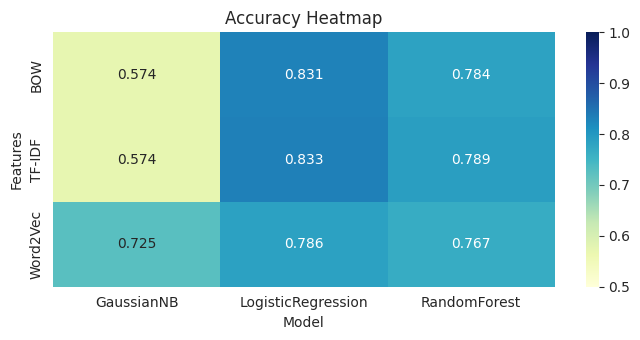

Best model: TF-IDF + LogisticRegression (Accuracy=0.8329, F1=0.8803)


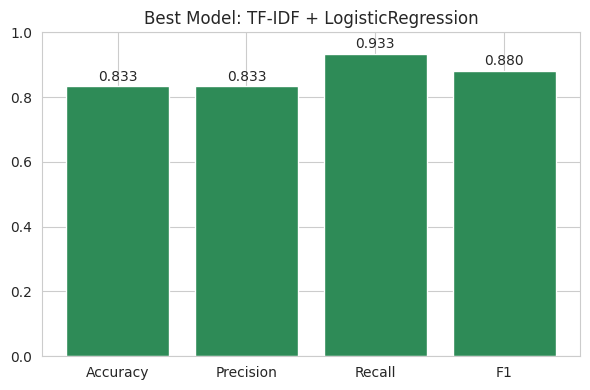

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_style("whitegrid")

# ---------- 1. Grouped bar charts: Accuracy and F1 ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, metric in zip(axes, ["Accuracy", "F1"]):
    sns.barplot(data=results_df, x="Model", y=metric, hue="Features",
                palette="Set2", ax=ax)
    ax.set_title(f"{metric} by Model and Feature Type")
    ax.set_ylim(0, 1)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)

axes[0].legend(title="Features", loc="lower right")
axes[1].get_legend().remove()
plt.tight_layout()
plt.show()

# ---------- 2. Heatmap: Accuracy (Features x Model) ----------
pivot = results_df.pivot(index="Features", columns="Model", values="Accuracy")

plt.figure(figsize=(7, 3.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.5, vmax=1)
plt.title("Accuracy Heatmap")
plt.tight_layout()
plt.show()

# ---------- 3. Precision / Recall / F1 for the best model ----------
best = results_df.iloc[0]
print(f"Best model: {best['Features']} + {best['Model']} "
      f"(Accuracy={best['Accuracy']:.4f}, F1={best['F1']:.4f})")

metrics = ["Accuracy", "Precision", "Recall", "F1"]
plt.figure(figsize=(6, 4))
bars = plt.bar(metrics, [best[m] for m in metrics], color="seagreen")
plt.bar_label(bars, fmt="%.3f", padding=2)
plt.ylim(0, 1)
plt.title(f"Best Model: {best['Features']} + {best['Model']}")
plt.tight_layout()
plt.show()